### Imports

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [39]:
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /home/luis/nltk_data...


True

### Load dataset

In [5]:
train_data = pd.read_csv('train.txt', sep='\t', header=None, names=['title', 'from', 'genre', 'director', 'plot'])

test_data = pd.read_csv('test_no_labels.txt', sep='\t', header=None, names=['title', 'from', 'director', 'plot'])

### Pre-processing

In [35]:
stop_words = set(stopwords.words('english')) #TODO: Maybe reduce the number of stopwords?
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r'\(\b([A-Z][a-z]*\s?)+\)', '', text)  # Remove text in brackets that starts with a capital letter (actors names)
    text = text.lower()  # Lowercase all characters
    text = re.sub(r'http\S+', '', text)  # Remove URLs #TODO: Remove this line?
    #text = re.sub(r"[^a-zA-Z+']", ' ', text)  # Keep only characters
    #text = re.sub(r'\s+[a-zA-Z]\s+', ' ', text + ' ')  # Keep words with length > 1 only
    text = "".join([i for i in text if i not in string.punctuation])
    words = word_tokenize(text)
    stopwords_ = stopwords.words('english')  # Remove stopwords
    text = " ".join([lemmatizer.lemmatize(i) for i in words if i not in stopwords_])
    text = re.sub("\s[\s]+", " ", text).strip()  # Remove repeated/leading/trailing spaces
    return text

train_data['Text_cleaning'] = train_data['plot'].apply(clean_text)
train_data['title'] = train_data['title'].apply(clean_text)

test_data['Text_cleaning'] = test_data['plot'].apply(clean_text)
test_data['title'] = test_data['title'].apply(clean_text)

train_data['Text_cleaning'].head()

0    sekhar graduate iim work business manager firm...
1    kris fowles go springwood diner meet exboyfrie...
2    cynthia traumatized death baby leaving bathtub...
3    four friend gangu abdul nihal gary form word g...
4    crisis middleclass family son fall love father...
Name: Text_cleaning, dtype: object

### Statistics

/tmp/ipykernel_6411/3180155325.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='genre' , data=train_data , order=train_data['genre'].value_counts().index, palette='viridis')


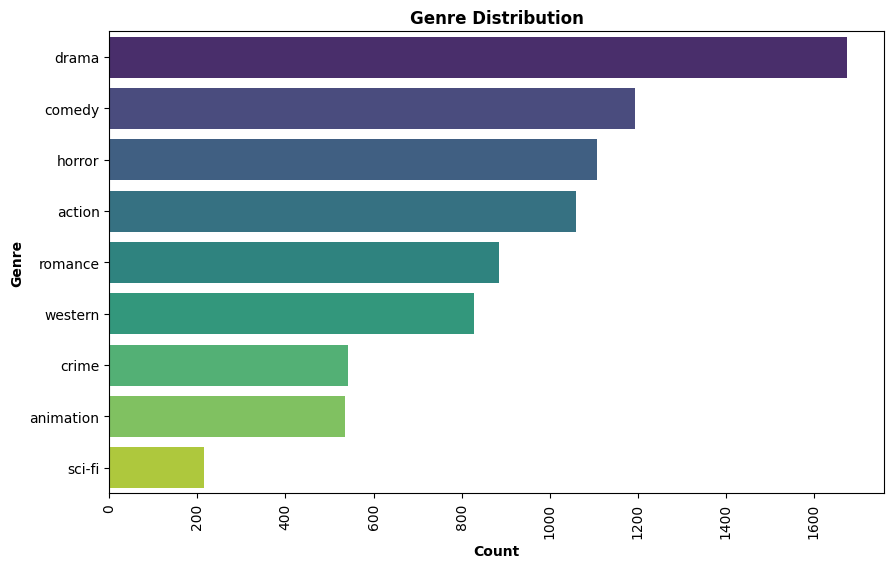

In [17]:
plt.figure(figsize=(10,6))
sns.countplot(y='genre' , data=train_data , order=train_data['genre'].value_counts().index, palette='viridis')
plt.title('Genre Distribution',fontweight='bold')
plt.xlabel('Count', fontweight='bold')
plt.ylabel('Genre', fontweight='bold')
plt.xticks(rotation=90)
plt.show()

In [32]:
print(train_data.head())

                  title       from    genre       director  \
0          ela cheppanu     Telugu  romance         Ramana   
1  nightmare elm street   American   horror   Samuel Bayer   
2       american gothic   American   horror     John Hough   
3                  gang  Bollywood    crime    Mazhar Khan   
4     intimate relation    British    drama  Charles Frank   

                                                plot  \
0  Sekhar (Tarun) is a graduate from IIM and work...   
1  Kris Fowles (Katie Cassidy) goes to the Spring...   
2  Cynthia is traumatized by the death of her bab...   
3  Four friends, Gangu (Jackie Shroff), Abdul (Na...   
4  Crisis in a middle-class family when the son f...   

                                       Text_cleaning  
0  sekhar graduate iim work business manager firm...  
1  kris fowles go springwood diner meet exboyfrie...  
2  cynthia traumatized death baby leaving bathtub...  
3  four friend gangu abdul nihal gary form word g...  
4  crisis middl

### Training the Model

In [4]:
vectorizer = CountVectorizer()

X_train = vectorizer.fit_transform(train_data['Text_cleaning'])
X_test = vectorizer.transform(test_data['Text_cleaning'])

# Split the data into training and validation sets
X = X_train
y = train_data['genre']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train a Multinomial Naive Bayes classifier
classifier = MultinomialNB()
classifier.fit(X_train, y_train)

MultinomialNB()

### Model Validation (Train 80% - Test 20%)

In [5]:
# Make predictions on the validation set
y_pred = classifier.predict(X_val)

# Evaluate the performance of the model
accuracy = accuracy_score(y_val, y_pred)
print("Validation Accuracy:", accuracy)
print(classification_report(y_val, y_pred))

Validation Accuracy: 0.6376631448104413
              precision    recall  f1-score   support

      action       0.60      0.62      0.61       202
   animation       0.92      0.68      0.78       115
      comedy       0.56      0.45      0.50       223
       crime       0.81      0.16      0.26       108
       drama       0.50      0.69      0.58       319
      horror       0.70      0.87      0.78       223
     romance       0.55      0.55      0.55       186
      sci-fi       0.75      0.23      0.35        39
     western       0.91      0.93      0.92       194

    accuracy                           0.64      1609
   macro avg       0.70      0.57      0.59      1609
weighted avg       0.66      0.64      0.62      1609



### Model Predictions

In [7]:
# Use the trained model to make predictions on the test data
X_test_predictions = classifier.predict(X_test)

# Save the predictions to 'results.txt' with each predicted genre in a new line
with open('results.txt', 'w') as file:
    for genre in X_test_predictions:
        file.write(genre + '\n')

print("Predictions saved to results.txt")

Predictions saved to results.txt


## SVM

In [44]:
stop_words = list(set(stopwords.words("english")))

## Vectorize data
tfidf_vectorizer = TfidfVectorizer(analyzer='word',smooth_idf=False) #ngram_range=(1, 3)

train_t = tfidf_vectorizer.fit_transform(train_data['Text_cleaning'] + train_data['title']) #FIXME: should I use the whole data? (or may be with the movie title)
test_t = tfidf_vectorizer.transform(test_data['Text_cleaning'] + test_data['title'])

svm = LinearSVC().fit(train_t, train_data['genre'])

predictions = svm.predict(test_t)

# Evaluate the performance of the model
#accuracy = accuracy_score(y_val, predictions)
#print("Accuracy SVM:", accuracy)
#print(classification_report(y_val, y_pred))

In [19]:
# Save the predictions to 'results.txt' with each predicted genre in a new line
with open('svm_results.txt', 'w') as file:
    for genre in predictions:
        file.write(genre + '\n')

print("Predictions saved to svm_results.txt")

Predictions saved to svm_results.txt


In [45]:
from sklearn.model_selection import cross_val_predict
# Cross validation
cv_predictions = cross_val_predict(svm, train_t, train_data['genre'], cv=8)

print("Accuracy: ", accuracy_score(train_data['genre'], cv_predictions)) 

Accuracy:  0.6484268125854993


### Confusion matrix

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ['drama', 'comedy', 'horror', 'action', 'romance', 'western', 'animation', 'crime', 'sci-fi']

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Display the confusion matrix
print("Confusion Matrix:")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()

# Show the plot
plt.show()

ValueError: At least one label specified must be in y_true

In [34]:
#NEED TO DOUBLE CHECK THIS

X = train_data['Text_cleaning']
y = train_data['genre']

##################################################################################

sum = 0

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=40)

##################################################################################
# Vectorize the text data using TF-IDF

vectorizer = TfidfVectorizer(analyzer='word',smooth_idf=False, stop_words=list(stop_words))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

################################################################################
# suport vector machine

svc = LinearSVC()

svc.fit(X_train_tfidf, y_train)

y_pred = svc.predict(X_test_tfidf)
sum = sum + accuracy_score(y_test, y_pred)

print("Accuracy: ", sum)

Accuracy:  0.6807453416149069
